In [1]:
# test reader loading and reading the files

from czmeltbench.data.reader import CZDataReader

reader = CZDataReader(
    "../data/raw"
)

case_ids = reader.list_cases()

print("Accepted DOE cases:", len(case_ids))

pos, mu, y = reader.load_arrays("sobol_000")

print("Coordinates:", pos.shape)
print("Parameters:", mu.shape)
print("Fields:", y.shape)

Accepted DOE cases: 254
Coordinates: (8181, 2)
Parameters: (3,)
Fields: (8181, 5)


In [2]:
# test for reference coordinates
# 
import numpy as np 

reference_pos = reader.load_reference_positions("base")

print("Referece mesh:", reference_pos.shape)

print(
    "Same node ordering:",
    np.array_equal(pos, reference_pos)
)

Referece mesh: (8181, 2)
Same node ordering: True


# Test mesh reconstruction

In [3]:
from czmeltbench.geometry.mesh import (
    LogicalMesh,
    build_logical_mesh
)

pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)

print("Mesh shape:", mesh.shape)
print("Radial nodes:", mesh.nr)
print("Axial levels:", mesh.nz)
print("Total nodes:", mesh.num_nodes)

Mesh shape: (81, 101)
Radial nodes: 101
Axial levels: 81
Total nodes: 8181


In [4]:
reconstructed_pos = mesh.original_coordinates()

print(
    "coordinates preserved:", np.array_equal(pos, reconstructed_pos)
)

coordinates preserved: True


In [5]:
import numpy as np
from czmeltbench.geometry.boundaries import (
    identify_boundaries,
    boundary_features,
    distance_features
)



In [6]:
# laod adnd classify nodes

pos, mu, y = reader.load_arrays("sobol_000")

masks = identify_boundaries(pos)

for name, mask in masks.items():
    print(f"{name:12s}: {mask.sum()}")

axis        : 81
bottom      : 101
wall        : 81
crystal     : 57
lid         : 45
interior    : 7821


In [7]:
# validate unique boundary counts
boundary_union = np.logical_or.reduce([
    masks[name] for name in (
        "axis", "bottom", "wall", "crystal", "lid"
    )
])

assert boundary_union.sum() == 360
assert masks["interior"].sum() == 7821
assert np.all(~boundary_union == masks["interior"])

print("Boundary classification validated")

Boundary classification validated


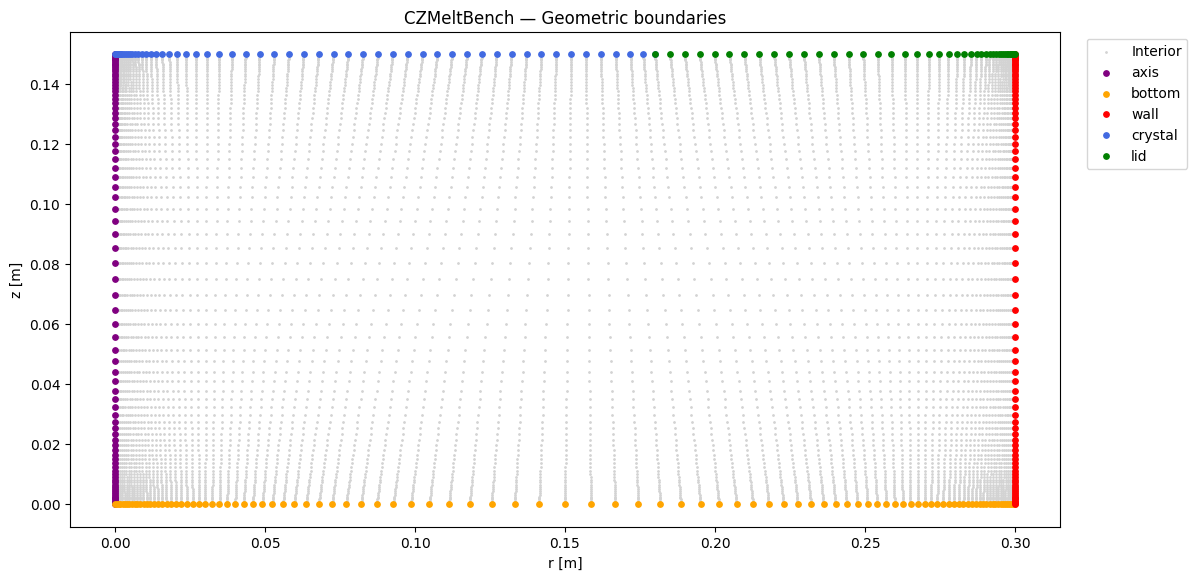

In [8]:
# Visualize boundary features

import matplotlib.pyplot as plt

names = ["axis", "bottom", "wall", "crystal", "lid"]

colors = [
    "purple", "orange", "red",
    "royalblue", "green"
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    pos[masks["interior"], 0],
    pos[masks["interior"], 1],
    s=1,
    color="lightgray",
    label="Interior",
)

for name, color in zip(names, colors):

    mask = masks[name]

    ax.scatter(
        pos[mask, 0],
        pos[mask, 1],
        s=15,
        color=color,
        label=name,
    )

ax.set_xlabel("r [m]")
ax.set_ylabel("z [m]")
ax.set_title("CZMeltBench — Geometric boundaries")
ax.set_aspect("equal")
ax.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

## TEst Bounndary condition implementationn

In [9]:
# import new module of BC

from czmeltbench.physics.boundary_conditions import (
    BoundaryConditions,
    compute_boundary_conditions,
    rpm_to_rad_per_sec,
)

from czmeltbench.constants import FIELD_COLUMNS

In [10]:
# load sim and calculate BCs

pos, mu, y = reader.load_arrays("sobol_000")

bc = compute_boundary_conditions(pos=pos, mu=mu)

print("Values shape:", bc.values.shape)
print("Mask shape:", bc.mask.shape)
print("Number of nodes:", bc.num_nodes)



Values shape: (8181, 5)
Mask shape: (8181, 5)
Number of nodes: 8181


In [11]:
for i, field in enumerate(FIELD_COLUMNS):
    print(
        f"{field:10s}: "
        f"{bc.mask[:, 1].sum()} nodes"
    )

u_r       : 281 nodes
u_z       : 281 nodes
u_swirl   : 281 nodes
p         : 281 nodes
T         : 281 nodes


# Test Feature from physics/features.py

In [12]:
from czmeltbench.physics.features import (
    FeatureConfig,
    NodeFeatures,
    build_node_features,
)

In [13]:
# load one simulation

pos, mu, y = reader.load_arrays("sobol_000")

In [14]:
# test 1: minimal features
minimal = build_node_features(pos,
                              mu,
                              config=FeatureConfig(
                                  include_parameters=True,
                                  include_boundaries=False,
                              ),)

print(minimal.x.shape)
print(minimal.columns)

(8181, 5)
('r', 'z', 'crystal_rpm', 'crucible_rpm', 't_hot')


In [15]:
# test 2 - boundary aware featuires

boundary_aware = build_node_features(
    pos, mu, config=FeatureConfig(
        include_parameters=True,
        include_boundaries=True,
    )
)

print(boundary_aware.x.shape)
print(boundary_aware.columns)

(8181, 10)
('r', 'z', 'crystal_rpm', 'crucible_rpm', 't_hot', 'boundary_axis', 'boundary_bottom', 'boundary_wall', 'boundary_crystal', 'boundary_lid')


In [16]:
# test 3 - explicit boundary conditions

explicit_bc = build_node_features(
    pos, mu, config=FeatureConfig(
        include_bc_values=True,
    ),
)

print(explicit_bc.x.shape)

(8181, 20)


In [17]:
# test 4 - geometry aware features

geometry_aware = build_node_features(
    pos, mu, config=FeatureConfig(
        include_bc_values=True,
        include_distances=True,
    )
)

print(geometry_aware.x.shape)

(8181, 25)


In [18]:
print(geometry_aware.columns)

wall_mask = geometry_aware.get_column(
    "boundary_wall"
)

wall_distance = geometry_aware.get_column(
    "distance_wall"
)

print("Wall nodes:", int(wall_mask.sum()))
print("Minimum wall distance:", wall_distance.min())

('r', 'z', 'crystal_rpm', 'crucible_rpm', 't_hot', 'boundary_axis', 'boundary_bottom', 'boundary_wall', 'boundary_crystal', 'boundary_lid', 'bc_value_u_r', 'bc_value_u_z', 'bc_value_u_swirl', 'bc_value_p', 'bc_value_T', 'bc_mask_u_r', 'bc_mask_u_z', 'bc_mask_u_swirl', 'bc_mask_p', 'bc_mask_T', 'distance_axis', 'distance_bottom', 'distance_wall', 'distance_crystal', 'distance_lid')
Wall nodes: 81
Minimum wall distance: 0.0


In [19]:
import pandas as pd

features_df = pd.DataFrame(
    geometry_aware.x,
    columns=geometry_aware.columns,
)

display(features_df.head())

,r,z,crystal_rpm,crucible_rpm,t_hot,boundary_axis,boundary_bottom,boundary_wall,boundary_crystal,boundary_lid,...,bc_mask_u_r,bc_mask_u_z,bc_mask_u_swirl,bc_mask_p,bc_mask_T,distance_axis,distance_bottom,distance_wall,distance_crystal,distance_lid
0,0.0,0.000000,10.896472,-2.670688,1774.352702,1.0,1.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,0.0,0.000000,0.3,0.150000,0.234307
1,0.0,0.000358,10.896472,-2.670688,1774.352702,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.000358,0.3,0.149642,0.234079
2,0.0,0.000741,10.896472,-2.670688,1774.352702,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.000741,0.3,0.149259,0.233834
3,0.0,0.001152,10.896472,-2.670688,1774.352702,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.001152,0.3,0.148848,0.233572
4,0.0,0.001592,10.896472,-2.670688,1774.352702,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.001592,0.3,0.148408,0.233291


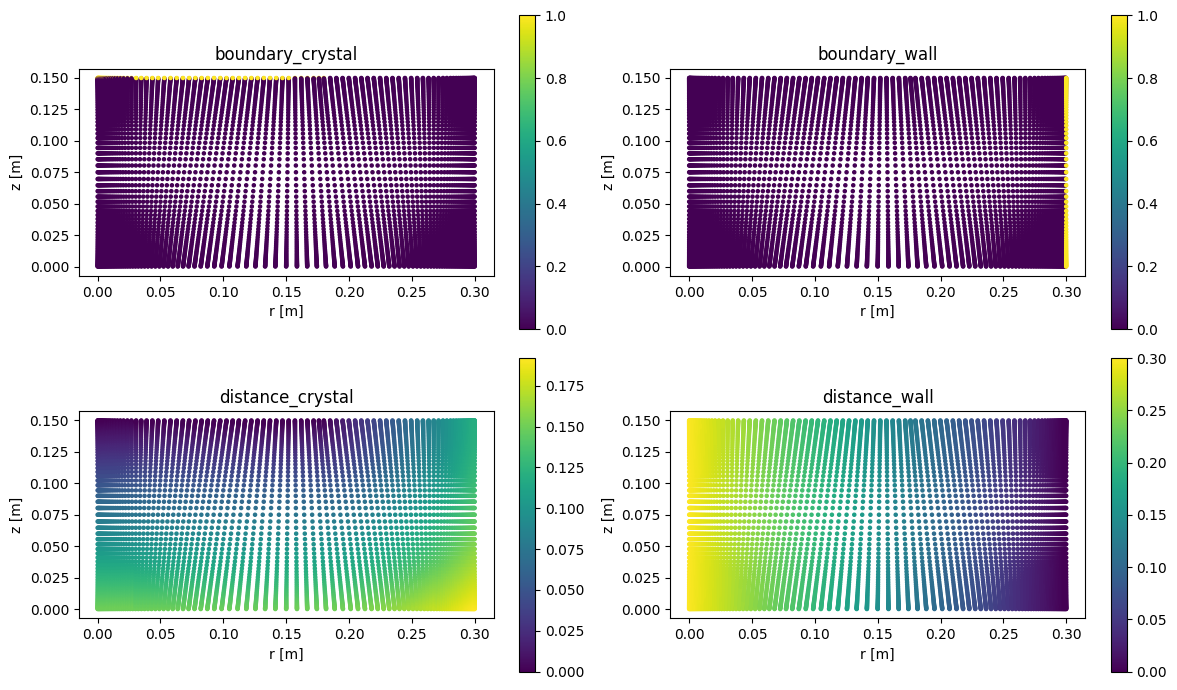

In [20]:
# Visualize
import matplotlib.pyplot as plt

feature_names = [
    "boundary_crystal",
    "boundary_wall",
    "distance_crystal",
    "distance_wall",
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, name in zip(axes.flat, feature_names):

    values = geometry_aware.get_column(name)

    sc = ax.scatter(
        pos[:, 0],
        pos[:, 1],
        c=values,
        cmap="viridis",
        s=5,
    )

    ax.set_title(name)
    ax.set_xlabel("r [m]")
    ax.set_ylabel("z [m]")
    ax.set_aspect("equal")

    fig.colorbar(sc, ax=ax)

plt.tight_layout()
plt.show()

# test  the connectivity 

In [21]:
from czmeltbench.geometry.mesh import build_logical_mesh

from czmeltbench.geometry.connectivity import (
    MeshConnectivity,
    build_connectivity,
)

pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos=pos)
graph = build_connectivity(mesh)

print("Logical mesh: ", mesh.shape)
print("Edge indices: ", graph.edge_index.shape)
print("Edge attributes: ", graph.edge_attr.shape)
print("Quadrilateral cells: ", graph.cells.shape)


Logical mesh:  (81, 101)
Edge indices:  (2, 32360)
Edge attributes:  (32360, 3)
Quadrilateral cells:  (8000, 4)


In [22]:
# verify grpah symmmetry
import numpy as np

# ede indices must reference original CFD node rowss
src = graph.edge_index[0]
dst = graph.edge_index[1]

expected_displacement = pos[dst] - pos[src]

np.testing.assert_allclose(
    graph.edge_attr[:, :2],
    expected_displacement,
)

# every directed edge must have a reverse.
edges = set(map(tuple, graph.edge_index.T.tolist()))

assert all(
    (v, u) in edges for u, v in edges
)

# self-loops should not exist.
assert not np.any(src == dst)

# No node field was modified.
np.testing.assert_array_equal(
    pos,
    mesh.original_coordinates(),
)

print("Graph topology and original node indexing verified.")

Graph topology and original node indexing verified.


In [23]:
# verify quadrilateraal cell orientation
cell_pos = pos[graph.cells]

r = cell_pos[:, :, 0]
z = cell_pos[:, :, 1]

signed_area = 0.5 * np.sum(
    r * np.roll(z, -1, axis=1) - np.roll(r, -1, axis=1) * z,
    axis=1,
)

print("Minimum cell area:", signed_area.min())
print("Maximum cell area:", signed_area.max())

assert np.all(signed_area > 0.0)

Minimum cell area: 5.9082382441316694e-08
Maximum cell area: 3.671873292568264e-05


In [24]:
# verify all 3 mesh resolutions

for resolution in ("coarse", "base", "fine"):
    reference_pos = reader.load_reference_positions(resolution)

    mesh = build_logical_mesh(reference_pos)
    graph = build_connectivity(mesh)

    print(
        resolution,
        "shape:", mesh.shape,
        "edges:", graph.num_edges,
        "cells:", graph.num_cells,
    )

coarse shape: (41, 51) edges: 8180 cells: 2000
base shape: (81, 101) edges: 32360 cells: 8000
fine shape: (161, 200) edges: 128078 cells: 31840


# TEst Quadrature module

In [25]:
from czmeltbench.geometry.mesh import build_logical_mesh
from czmeltbench.geometry.connectivity import build_connectivity
from czmeltbench.geometry.quadrature import compute_mesh_quadrature

pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)
graph = build_connectivity(mesh)

quad = compute_mesh_quadrature(pos=pos,
                               cells=graph.cells)

print("Logical mesh:", mesh.shape)
print("Cell areas:", quad.cell_area.shape)
print("Cell volumes:", quad.cell_volume.shape)
print("Node volume weights:", quad.node_volume_weights.shape)

print("Total area [m²]:", quad.total_area)
print("Total volume [m³]:", quad.total_volume)

Logical mesh: (81, 101)
Cell areas: (8000,)
Cell volumes: (8000,)
Node volume weights: (8181,)
Total area [m²]: 0.04499999999999996
Total volume [m³]: 0.042411500823462164


In [26]:
pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)
graph = build_connectivity(mesh)

In [27]:
import numpy as np

print("Logical mesh:", mesh.shape)
print("Cells:", graph.cells.shape)

# Inspect the first quadrilateral
print("First cell node IDs:")
print(graph.cells[0])

print("First cell coordinates [r, z]:")
print(pos[graph.cells[0]])

# Verify original CFD coordinates are preserved
np.testing.assert_array_equal(
    mesh.original_coordinates(),
    pos,
)

Logical mesh: (81, 101)
Cells: (8000, 4)
First cell node IDs:
[  0 188 187   1]
First cell coordinates [r, z]:
[[0.         0.        ]
 [0.00057387 0.        ]
 [0.00057302 0.00035765]
 [0.         0.00035765]]


In [28]:
vertices = pos[graph.cells]

r = vertices[:, :, 0]
z = vertices[:, :, 1]

gauss_points = (
    -1.0 / np.sqrt(3.0),
     1.0 / np.sqrt(3.0),
)

all_jacobians = []

for xi in gauss_points:
    for eta in gauss_points:

        dxi = 0.25 * np.array([
            -(1.0 - eta),
             (1.0 - eta),
             (1.0 + eta),
            -(1.0 + eta),
        ])

        deta = 0.25 * np.array([
            -(1.0 - xi),
            -(1.0 + xi),
             (1.0 + xi),
             (1.0 - xi),
        ])

        dr_dxi = r @ dxi
        dr_deta = r @ deta

        dz_dxi = z @ dxi
        dz_deta = z @ deta

        det_j = (
            dr_dxi * dz_deta
            - dr_deta * dz_dxi
        )

        all_jacobians.append(det_j)

jacobians = np.stack(all_jacobians, axis=1)

invalid_cells = np.flatnonzero(
    np.any(jacobians <= 0.0, axis=1)
)

print("Minimum Jacobian:", jacobians.min())
print("Invalid cell count:", len(invalid_cells))

if len(invalid_cells) > 0:
    i = int(invalid_cells[0])

    print("First invalid cell:", i)
    print("Node IDs:", graph.cells[i])
    print("Coordinates:", pos[graph.cells[i]])
    print("Jacobians:", jacobians[i])

Minimum Jacobian: 1.4745414222681233e-08
Invalid cell count: 0


In [29]:
pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)
graph = build_connectivity(mesh)

print("Mesh shape:", mesh.shape)
print("Cell shape:", graph.cells.shape)

print("\nFirst cell indices:")
print(graph.cells[0])

print("\nFirst cell coordinates:")
print(pos[graph.cells[0]])

# Calculate signed area for every quadrilateral
vertices = pos[graph.cells]

r = vertices[:, :, 0]
z = vertices[:, :, 1]

signed_areas = 0.5 * np.sum(
    r * np.roll(z, -1, axis=1)
    - np.roll(r, -1, axis=1) * z,
    axis=1,
)

print("\nMinimum signed area:", signed_areas.min())
print("Maximum signed area:", signed_areas.max())
print("Non-positive areas:", np.sum(signed_areas <= 0))

Mesh shape: (81, 101)
Cell shape: (8000, 4)

First cell indices:
[  0 188 187   1]

First cell coordinates:
[[0.         0.        ]
 [0.00057387 0.        ]
 [0.00057302 0.00035765]
 [0.         0.00035765]]

Minimum signed area: 5.9082382441316694e-08
Maximum signed area: 3.671873292568264e-05
Non-positive areas: 0


# test  for Quantites in physics/quantites

In [30]:
from czmeltbench.geometry.mesh import build_logical_mesh
from czmeltbench.geometry.connectivity import build_connectivity
from czmeltbench.geometry.quadrature import compute_mesh_quadrature
from czmeltbench.physics.quantities import calculate_quantities

pos, mu, y = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)
graph = build_connectivity(mesh)

quad = compute_mesh_quadrature(pos=pos,
                               cells=graph.cells)

qoi = calculate_quantities(
    y,
    volume_weights=quad.node_volume_weights,
)

for name, value in qoi.items():
    print(f"{name:25s}: {value:.6f}")

max_meridional           : 0.018631
rms_meridional           : 0.006505
max_swirl                : 0.201479
max_total                : 0.201479
mean_T                   : 1731.684882
min_T                    : 1685.000000
max_T                    : 1774.352702
delta_T                  : 89.352702
volume_mean_T            : 1737.287813
volume_rms_meridional    : 0.007460
volume_rms_total         : 0.059141


In [31]:
# Crate datafrom of data

import pandas as pd

qoi_df = pd.DataFrame([qoi], index=["sobol_000"])

display(qoi_df.T)

,sobol_000
max_meridional,0.018631
rms_meridional,0.006505
max_swirl,0.201479
max_total,0.201479
mean_T,1731.684882
min_T,1685.000000
max_T,1774.352702
delta_T,89.352702
volume_mean_T,1737.287813
volume_rms_meridional,0.007460


In [32]:
# verify that original mesh are not changed
y_original = y.copy()

_ = calculate_quantities(
    y,
    volume_weights=quad.node_volume_weights,
)

np.testing.assert_array_equal(y, y_original)

print("Original CFD fields preserved.")

Original CFD fields preserved.


# test Metrics and Evaluation

In [33]:
import numpy as np

from czmeltbench.geometry.mesh import build_logical_mesh
from czmeltbench.geometry.connectivity import build_connectivity
from czmeltbench.geometry.quadrature import compute_mesh_quadrature
from czmeltbench.evaluation.metrics import evaluate_fields

pos, mu, y_true = reader.load_arrays("sobol_000")

mesh = build_logical_mesh(pos)
graph = build_connectivity(mesh)

quad = compute_mesh_quadrature(
    pos=pos,
    cells=graph.cells,
)

# Synthetic prediction for software testing only.
y_pred = y_true.copy()
y_pred[:, 0] += 0.001
y_pred[:, 4] += 2.0

results = evaluate_fields(
    y_true=y_true,
    y_pred=y_pred,
    volume_weights=quad.node_volume_weights,
)

display(results)

,mae,rmse,relative_l2,volume_mae,volume_rmse,volume_relative_l2
field,,,,,,
u_r,0.001,0.001,0.220153,0.001,0.001,0.180289
u_z,0.000,0.000,0.000000,0.000,0.000,0.000000
u_swirl,0.000,0.000,0.000000,0.000,0.000,0.000000
p,0.000,0.000,0.000000,0.000,0.000,0.000000
T,2.000,2.000,0.001155,2.000,2.000,0.001151


In [34]:
# interior evalaution
from czmeltbench.geometry.boundaries import identify_boundaries

masks = identify_boundaries(pos)

interior_results = evaluate_fields(
    y_true=y_true,
    y_pred=y_pred,
    volume_weights=quad.node_volume_weights,
    node_mask=masks["interior"],
)

display(interior_results)

,mae,rmse,relative_l2,volume_mae,volume_rmse,volume_relative_l2
field,,,,,,
u_r,0.001,0.001,0.215255,0.001,0.001,0.179963
u_z,0.000,0.000,0.000000,0.000,0.000,0.000000
u_swirl,0.000,0.000,0.000000,0.000,0.000,0.000000
p,0.000,0.000,0.000000,0.000,0.000,0.000000
T,2.000,2.000,0.001155,2.000,2.000,0.001151


# test for Evaluator

In [35]:
from czmeltbench.evaluation.evaluator import CaseEvaluator

pos, mu,  y_true = reader.load_arrays("sobol_000")

evaluator = CaseEvaluator(reader)

result = evaluator.evaluate(
    case_id="sobol_000",
    y_pred=y_true.copy(),
    prediction_pos=pos.copy(),
    region="all",
)

print("Case:", result.case_id)
print("Region:", result.region)
print("Total nodes: ", result.num_nodes)
print("Evaluated nodes: ", result.num_evaluated_nodes)
print("Melt volume [m^3]", result.total_volume)

Case: sobol_000
Region: all
Total nodes:  8181
Evaluated nodes:  8181
Melt volume [m^3] 0.042411500823462164


In [36]:
# test with synthetic prediction errors
y_pred = y_true.copy()

# Add known synthetic prediction errors.
y_pred[:, 0] += 0.001
y_pred[:, 4] += 2.0

result = evaluator.evaluate(
    case_id="sobol_000",
    y_pred=y_pred,
    prediction_pos=pos,
)

display(result.metrics)

,mae,rmse,relative_l2,volume_mae,volume_rmse,volume_relative_l2
field,,,,,,
u_r,0.001,0.001,0.220153,0.001,0.001,0.180289
u_z,0.000,0.000,0.000000,0.000,0.000,0.000000
u_swirl,0.000,0.000,0.000000,0.000,0.000,0.000000
p,0.000,0.000,0.000000,0.000,0.000,0.000000
T,2.000,2.000,0.001155,2.000,2.000,0.001151


In [37]:
# interior only evalaution

interior_result = evaluator.evaluate(
    case_id="sobol_000",
    y_pred=y_pred,
    prediction_pos=pos,
    region="interior",
)

print(
    "Interior nodes:",
    interior_result.num_evaluated_nodes,
)

display(interior_result.metrics)

Interior nodes: 7821


,mae,rmse,relative_l2,volume_mae,volume_rmse,volume_relative_l2
field,,,,,,
u_r,0.001,0.001,0.215255,0.001,0.001,0.179963
u_z,0.000,0.000,0.000000,0.000,0.000,0.000000
u_swirl,0.000,0.000,0.000000,0.000,0.000,0.000000
p,0.000,0.000,0.000000,0.000,0.000,0.000000
T,2.000,2.000,0.001155,2.000,2.000,0.001151


# Test benchmark using two real DOE simualtions

In [42]:
import importlib
import czmeltbench.evaluation.benchmark as benchmark_module

importlib.reload(benchmark_module)

CasePrediction = benchmark_module.CasePrediction
BenchmarkEvaluator = benchmark_module.BenchmarkEvaluator


In [43]:
case_ids = ["sobol_000", "sobol_001"]

predictions = {}

for case_id in case_ids:
    pos, mu, y = reader.load_arrays(case_id)

    predictions[case_id] = CasePrediction(
        pos=pos.copy(),
        y=y.copy(),
    )

benchmark = BenchmarkEvaluator(CaseEvaluator(reader))

result = benchmark.evaluate(
    predictions=predictions,
    expected_case_ids=case_ids,
    region="all",
)

print("Evaluated cases:", result.num_cases)

display(result.case_metadata)
display(result.summary)

Evaluated cases: 2


,num_nodes,num_evaluated_nodes,total_volume,crystal_rpm,crucible_rpm,t_hot
case_id,,,,,,
sobol_000,8181,8181,0.042412,10.896472,-2.670688,1774.352702
sobol_001,8181,8181,0.042412,17.917017,-6.062550,1757.430408


valid_cases  mean  std  min  max
field   metric                                              
u_r     mae                           2   0.0  0.0  0.0  0.0
        rmse                          2   0.0  0.0  0.0  0.0
        relative_l2                   2   0.0  0.0  0.0  0.0
        volume_mae                    2   0.0  0.0  0.0  0.0
        volume_rmse                   2   0.0  0.0  0.0  0.0
        volume_relative_l2            2   0.0  0.0  0.0  0.0
u_z     mae                           2   0.0  0.0  0.0  0.0
        rmse                          2   0.0  0.0  0.0  0.0
        relative_l2                   2   0.0  0.0  0.0  0.0
        volume_mae                    2   0.0  0.0  0.0  0.0
        volume_rmse                   2   0.0  0.0  0.0  0.0
        volume_relative_l2            2   0.0  0.0  0.0  0.0
u_swirl mae                           2   0.0  0.0  0.0  0.0
        rmse                          2   0.0  0.0  0.0  0.0
        relative_l2                   2   0.0  0.0  0.0  0.0
        volume_mae                    2   0.0  0.0  0.0  0.0
        volume_rmse                   2   0.0  0.0  0.0  0.0
        volume_relative_l2            2   0.0  0.0  0.0  0.0
p       mae                           2   0.0  0.0  0.0  0.0
        rmse                          2   0.0  0.0  0.0  0.0
        relative_l2                   2   0.0  0.0  0.0  0.0
        volume_mae                    2   0.0  0.0  0.0  0.0
        volume_rmse                   2   0.0  0.0  0.0  0.0
        volume_relative_l2            2   0.0  0.0  0.0  0.0
T       mae                           2   0.0  0.0  0.0  0.0
        rmse                          2   0.0  0.0  0.0  0.0
        relative_l2                   2   0.0  0.0  0.0  0.0
        volume_mae                    2   0.0  0.0  0.0  0.0
        volume_rmse                   2   0.0  0.0  0.0  0.0
        volume_relative_l2            2   0.0  0.0  0.0  0.0